In [1]:
#importar librerias

import pandas as pd
import numpy as np
import zipfile
import os


In [2]:
from google.colab import files

archivo_subido_2024 = files.upload()

Saving 2024.zip to 2024.zip


In [3]:
from google.colab import files

archivo_subido_2025 = files.upload()

Saving 2025.zip to 2025.zip


In [4]:
from google.colab import files

archivo_subido_2026 = files.upload()

Saving 2026.zip to 2026.zip


Consolidacion y depuracion de la base de datos

In [5]:
# CONSOLIDACIÓN DE LA BASE HISTÓRICA
# Enero 2024 - mayo 2026


datos_historicos = []

columnas_necesarias = [
    "CODIGO_PROPIO",
    "DES_MEDICAMENTO",
    "CANTIDAD",
    "BODEGA",
    "DES_UF",
    "MES",
    "AÑO"
]

def cargar_zip(ruta_zip):

    datos = []

    with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:

        archivos_excel = [
            archivo
            for archivo in archivo_zip.namelist()
            if archivo.lower().endswith(".xlsx")
        ]

        for archivo in archivos_excel:

            with archivo_zip.open(archivo) as archivo_excel:

                # Primero se lee el archivo completo
                df = pd.read_excel(archivo_excel)

                # Normalizar nombres de columnas
                df.columns = (
                    df.columns
                    .astype(str)
                    .str.strip()
                    .str.upper()
                )

                # Conservar únicamente las variables necesarias
                df = df[columnas_necesarias].copy()

                datos.append(df)

    return datos


# ============================================
# 2024
# ============================================

datos_2024 = cargar_zip("2024.zip")

print("Archivos 2024 cargados:", len(datos_2024))


# ============================================
# 2025
# ============================================

datos_2025 = cargar_zip("2025.zip")

print("Archivos 2025 cargados:", len(datos_2025))


# ============================================
# 2026
# ============================================

datos_2026 = cargar_zip("2026.zip")

print("Archivos 2026 cargados:", len(datos_2026))


# ============================================
# UNIFICACIÓN
# ============================================

datos_historicos = datos_2024 + datos_2025 + datos_2026

base_historica = pd.concat(
    datos_historicos,
    ignore_index=True
)

print(
    "Total de registros de la base histórica:",
    len(base_historica)
)

Archivos 2024 cargados: 12
Archivos 2025 cargados: 12
Archivos 2026 cargados: 5
Total de registros de la base histórica: 11625461


In [6]:
# Liberar memoria de las bases mensuales
del datos_2024
del datos_2025
del datos_2026
del datos_historicos

import gc
gc.collect()

print("Memoria temporal liberada.")
print("Registros en base_historica:", len(base_historica))

Memoria temporal liberada.
Registros en base_historica: 11625461


In [7]:
from google.colab import files

archivo_bodegas = files.upload()

Saving bodegas.xlsx to bodegas.xlsx


In [8]:
bodegas = pd.read_excel("bodegas.xlsx")

bodegas.columns = (
    bodegas.columns
    .astype(str)
    .str.strip()
)

print("Registros de la base de Bodegas:", len(bodegas))
print("Columnas:")
print(bodegas.columns.tolist())

bodegas.head()

Registros de la base de Bodegas: 37
Columnas:
['Bodega', 'Servicio', 'Servicio Farmaceutico', 'Sede', 'Se utiliza']


,Bodega,Servicio,Servicio Farmaceutico,Sede,Se utiliza
0,130,Priopios Prado,Cirugia Ambulatoria,Ambulatoria,Si
1,155,Regulados Prado,Cirugia Ambulatoria,Ambulatoria,Si
2,820,Hospitalizacion,Hospitalizacion,Principal,Si
3,821,Urgencias,Urgencias,Principal,Si
4,823,Prodiagnostico - Radiologia,Hospitalizacion,Principal,Si


In [9]:
# RELACIÓN BASE HISTÓRICA - BODEGAS


# Estandarizar el código de bodega en la base maestra
bodegas["BODEGA_KEY"] = (
    pd.to_numeric(bodegas["Bodega"], errors="coerce")
)

# Crear un mapa de código de bodega → condición de utilización
mapa_uso_bodega = (
    bodegas
    .drop_duplicates("BODEGA_KEY")
    .set_index("BODEGA_KEY")["Se utiliza"]
)

# Relacionar cada registro histórico con la condición
# de utilización de su bodega
bodega_key_historica = pd.to_numeric(
    base_historica["BODEGA"],
    errors="coerce"
)

uso_bodega = bodega_key_historica.map(mapa_uso_bodega)

# Verificar correspondencia
sin_clasificacion = uso_bodega.isna().sum()

print("Registros históricos sin clasificación de bodega:", sin_clasificacion)

# Contar registros según condición institucional
print("\nRegistros por condición de utilización:")
print(uso_bodega.value_counts(dropna=False))

Registros históricos sin clasificación de bodega: 0

Registros por condición de utilización:
BODEGA
Si                                                                                                                                                       11391780
Solo en esta bodega dejar la BOLSA EVA NUTRICION PARENTERAL 1000 ML - BOLSA EVA NUTRICION PARENTERAL 3000 ML - BOLSA EVA NUTRICION PARENTERAL 2000 ML      219897
No                                                                                                                                                          13784
Name: count, dtype: int64


In [10]:
# Productos registrados en la bodega 829
productos_829 = (
    base_historica[
        pd.to_numeric(base_historica["BODEGA"], errors="coerce") == 829
    ][
        ["CODIGO_PROPIO", "DES_MEDICAMENTO"]
    ]
    .drop_duplicates()
    .sort_values("DES_MEDICAMENTO")
)

print("Número de productos diferentes en bodega 829:", len(productos_829))

productos_829

Número de productos diferentes en bodega 829: 61


,CODIGO_PROPIO,DES_MEDICAMENTO
5794967,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6240,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6357,11515,BOLSA EVA NUTRICION PARENTERAL 3000 ML
786401,11482,BOLSA EVA NUTRICION PARENTERAL 500 ML.
5786841,11474,NPT ACIDO ASCORBICO ML (VITAMINA C)
...,...,...
493246,100006537,PREPARACION MEDICAMENTOS ESTERILES PEDIATRIA (...
493945,36689073,PREPARACION QUIMIOTERAPIA BOLSA X 1000 ML
492600,100017480,PREPARACION QUIMIOTERAPIA JERINGA
492603,100017479,PREPARACION QUIMIOTERAPIA MINIBOLSA


In [11]:
# Identificar las bolsas EVA de nutrición parenteral permitidas
# en la bodega 829

productos_permitidos_829 = productos_829[
    productos_829["DES_MEDICAMENTO"]
    .astype(str)
    .str.upper()
    .str.contains(
        "BOLSA EVA NUTRICION PARENTERAL",
        na=False
    )
]

productos_permitidos_829

,CODIGO_PROPIO,DES_MEDICAMENTO
5794967,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6240,11483,BOLSA EVA NUTRICION PARENTERAL 1000 ML
6357,11515,BOLSA EVA NUTRICION PARENTERAL 3000 ML
786401,11482,BOLSA EVA NUTRICION PARENTERAL 500 ML.
5960376,100017917,NPT BOLSA EVA NUTRICION PARENTERAL 2000 ML
5786852,11515,NPT BOLSA EVA NUTRICION PARENTERAL 3000 ML
5937679,11515,NPT BOLSA EVA NUTRICION PARENTERAL 3000 ML


In [13]:

# CRITERIOS DE DEPURACIÓN

# Normalizar descripción de los productos
descripcion = (
    base_historica["DES_MEDICAMENTO"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# 1. Productos precedidos por NPT
es_npt = descripcion.str.startswith("NPT")

# 2. Bodegas clasificadas institucionalmente como "No"
es_bodega_no = (
    uso_bodega
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("NO")
)

# 3. Identificar bodega 829
es_bodega_829 = (
    pd.to_numeric(
        base_historica["BODEGA"],
        errors="coerce"
    ) == 829
)

# 4. Productos permitidos en bodega 829
productos_permitidos_829 = [
    "BOLSA EVA NUTRICION PARENTERAL 500 ML",
    "BOLSA EVA NUTRICION PARENTERAL 1000 ML",
    "BOLSA EVA NUTRICION PARENTERAL 3000 ML"
]

es_producto_permitido_829 = descripcion.isin(
    productos_permitidos_829
)

# 5. En bodega 829 se excluyen los productos
# que no estén dentro de los permitidos
excluir_829 = (
    es_bodega_829 &
    ~es_producto_permitido_829
)

# 6. Criterio final de exclusión
# Un registro se elimina si:
# - pertenece a una bodega "No", O
# - es un producto NPT, O
# - pertenece a la bodega 829 pero no es un producto permitido.

excluir = (
    es_bodega_no |
    es_npt |
    excluir_829
)

# RESUMEN


print("Registros iniciales:", len(base_historica))
print("Bodegas clasificadas como No:", es_bodega_no.sum())
print("Productos NPT:", es_npt.sum())
print("Registros excluidos por regla de bodega 829:", excluir_829.sum())
print("Registros que cumplen algún criterio de exclusión:", excluir.sum())
print("Registros que permanecerían:", (~excluir).sum())

Registros iniciales: 11625461
Bodegas clasificadas como No: 13784
Productos NPT: 214144
Registros excluidos por regla de bodega 829: 208597
Registros que cumplen algún criterio de exclusión: 240553
Registros que permanecerían: 11384908


In [14]:
# COMPROBACIÓN DEL SOLAPAMIENTO DE CRITERIOS


print(
    "Bodega 829 - registros totales:",
    es_bodega_829.sum()
)

print(
    "Bodega 829 - registros permitidos:",
    (es_bodega_829 & es_producto_permitido_829).sum()
)

print(
    "Bodega 829 - registros excluidos:",
    excluir_829.sum()
)

print(
    "\nSolapamiento entre Bodega No y NPT:",
    (es_bodega_no & es_npt).sum()
)

print(
    "Solapamiento entre Bodega 829 y NPT:",
    (es_bodega_829 & es_npt).sum()
)

print(
    "Solapamiento entre Bodega 829 y Bodega No:",
    (es_bodega_829 & es_bodega_no).sum()
)

print(
    "\nRegistros que cumplen los 3 criterios:",
    (es_bodega_no & es_npt & es_bodega_829).sum()
)

Bodega 829 - registros totales: 219897
Bodega 829 - registros permitidos: 11300
Bodega 829 - registros excluidos: 208597

Solapamiento entre Bodega No y NPT: 0
Solapamiento entre Bodega 829 y NPT: 195972
Solapamiento entre Bodega 829 y Bodega No: 0

Registros que cumplen los 3 criterios: 0


In [15]:
# DEPURACIÓN DEFINITIVA DE LA BASE HISTÓRICA

registros_iniciales = len(base_historica)

# Aplicar los criterios de exclusión
base_historica = base_historica[
    ~excluir
].reset_index(drop=True)

registros_finales = len(base_historica)

print("Registros iniciales:", registros_iniciales)
print("Registros excluidos:", registros_iniciales - registros_finales)
print("Registros finales:", registros_finales)

Registros iniciales: 11625461
Registros excluidos: 240553
Registros finales: 11384908


In [16]:
# Liberar variables auxiliares utilizadas en la depuración

del uso_bodega
del bodega_key_historica
del mapa_uso_bodega
del descripcion
del es_npt
del es_bodega_no
del es_bodega_829
del es_producto_permitido_829
del excluir_829
del excluir

import gc
gc.collect()

print("Variables auxiliares liberadas.")
print("Base analítica final:", len(base_historica))

Variables auxiliares liberadas.
Base analítica final: 11384908


In [17]:
# CREACIÓN DE LA VARIABLE TEMPORAL PERIODO


orden_meses = {
    "ENERO": 1,
    "FEBRERO": 2,
    "MARZO": 3,
    "ABRIL": 4,
    "MAYO": 5,
    "JUNIO": 6,
    "JULIO": 7,
    "AGOSTO": 8,
    "SEPTIEMBRE": 9,
    "OCTUBRE": 10,
    "NOVIEMBRE": 11,
    "DICIEMBRE": 12
}

# Convertir el nombre del mes a número
base_historica["MES_NUMERO"] = (
    base_historica["MES"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map(orden_meses)
)

# Crear una fecha representativa del primer día de cada mes
base_historica["PERIODO"] = pd.to_datetime(
    base_historica["AÑO"].astype(int).astype(str)
    + "-"
    + base_historica["MES_NUMERO"].astype(int).astype(str)
    + "-01"
)

print("Variable PERIODO creada correctamente.")
print("Período inicial:", base_historica["PERIODO"].min())
print("Período final:", base_historica["PERIODO"].max())
print("Períodos únicos:", base_historica["PERIODO"].nunique())

Variable PERIODO creada correctamente.
Período inicial: 2024-01-01 00:00:00
Período final: 2026-05-01 00:00:00
Períodos únicos: 29


In [18]:
# CONSUMO TOTAL POR PERIODO


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Número de períodos analizados:", len(consumo_mensual))

consumo_mensual

Número de períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [19]:
# RESUMEN DEL COMPORTAMIENTO TEMPORAL


# Estadísticos generales del consumo mensual
resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

print("RESUMEN GENERAL")
resumen_temporal

RESUMEN GENERAL


,Indicador,Valor
0,Consumo mensual mínimo,1.153981e+06
1,Consumo mensual máximo,3.426907e+07
2,Promedio mensual,9.429090e+06


In [20]:
# CONSUMO TOTAL Y PROMEDIO POR AÑO


consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,105435473.0,8.786289e+06
2,2026,143677479.0,2.873550e+07


In [21]:
# VARIACIÓN DEL CONSUMO ANUAL


consumo_anual["Variacion_%"] = (
    consumo_anual["Consumo_total"]
    .pct_change()
    .mul(100)
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual,Variacion_%
0,2024,24330665.0,2.027555e+06,NaN
1,2025,105435473.0,8.786289e+06,333.343984
2,2026,143677479.0,2.873550e+07,36.270531


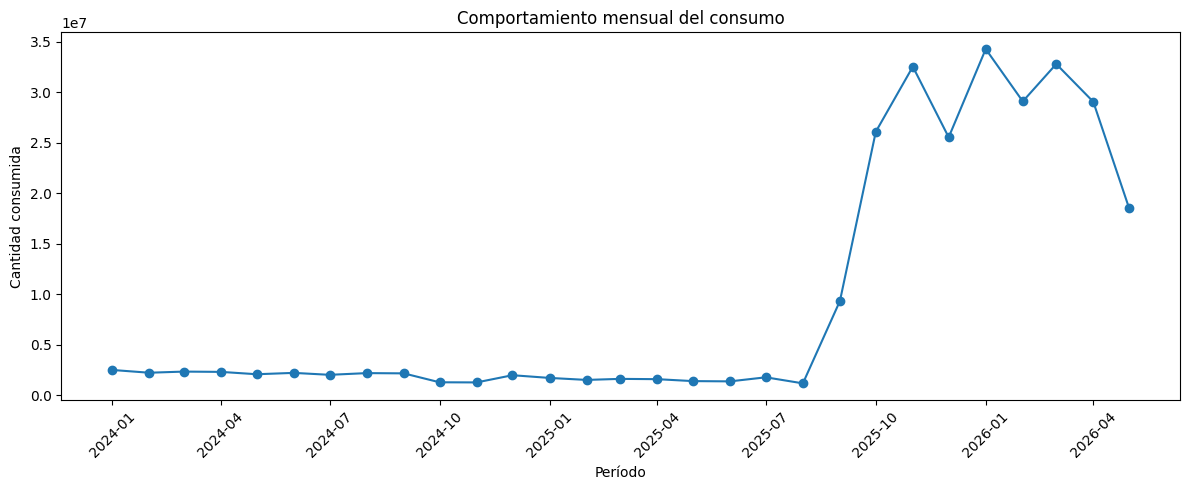

In [22]:
import matplotlib.pyplot as plt


# GRÁFICA DEL COMPORTAMIENTO TEMPORAL


plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.title("Comportamiento mensual del consumo")
plt.xlabel("Período")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [23]:
# IDENTIFICACIÓN DEL CAMBIO MÁS MARCADO

consumo_mensual["Variacion_mensual_%"] = (
    consumo_mensual["CANTIDAD"]
    .pct_change()
    .mul(100)
)

# Mostrar los meses con mayores aumentos y disminuciones
cambios_mensuales = (
    consumo_mensual[
        ["PERIODO", "CANTIDAD", "Variacion_mensual_%"]
    ]
    .sort_values("Variacion_mensual_%", ascending=False)
)

cambios_mensuales.head(5)

,PERIODO,CANTIDAD,Variacion_mensual_%
20,2025-09-01,9314067.0,707.124814
21,2025-10-01,26075524.0,179.958519
11,2024-12-01,1960629.0,57.175107
24,2026-01-01,34269070.0,34.229729
18,2025-07-01,1753741.0,29.833265


In [24]:
print("Meses con mayores disminuciones:")

cambios_mensuales.tail(5)

Meses con mayores disminuciones:


,PERIODO,CANTIDAD,Variacion_mensual_%
23,2025-12-01,25530164.0,-21.505016
19,2025-08-01,1153981.0,-34.198893
28,2026-05-01,18494797.0,-36.322083
9,2024-10-01,1260366.0,-41.230034
0,2024-01-01,2482230.0,NaN


In [25]:
# VALIDACIÓN DE CANTIDADES NULAS O NEGATIVAS


registros_no_positivos = base_historica[
    base_historica["CANTIDAD"] <= 0
]

print(
    "Registros con cantidad cero o negativa:",
    len(registros_no_positivos)
)

print(
    "Registros con cantidad negativa:",
    (base_historica["CANTIDAD"] < 0).sum()
)

print(
    "Registros con cantidad igual a cero:",
    (base_historica["CANTIDAD"] == 0).sum()
)

Registros con cantidad cero o negativa: 68
Registros con cantidad negativa: 68
Registros con cantidad igual a cero: 0


In [26]:
registros_no_positivos[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "CANTIDAD",
        "BODEGA",
        "DES_UF",
        "MES",
        "AÑO"
    ]
].sort_values(
    ["AÑO", "MES", "CANTIDAD"]
)

,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
6364380,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-100.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364381,3466,MASCARILLA FACIAL DESECHABLE RESORTADA,-50.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364425,225448,CUCHILLA QUIRURGICA PARA MAQUINA CLIPPER INALA...,-10.0,885,Cirugia - Bloque 3 - Piso 5,Agosto,2025
6369256,6086,VENDA ALGODON LAMINADO 3 X 5 YARDAS,-4.0,885,Servicio Transfusional - Bloque 1 - Piso 1,Agosto,2025
7800171,100004768,PAPEL DESFIBRILADOR MINDRAY BENEHEART D3 ROLLO...,-1.0,885,UCI Cardiovascular - Bloque 3 - Piso 7,Julio,2025
...,...,...,...,...,...,...,...
11378627,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,-15.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372019,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372020,10332,DEXTROSA EN AGUA DESTILADA 50% SOLUCION INYECT...,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11383014,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-6.0,885,Camillas SAI Adultos - Bloque 3 - Urgencias,Mayo,2026


In [27]:
# REVISIÓN DE LOS REGISTROS CON CANTIDAD NEGATIVA


registros_negativos = base_historica[
    base_historica["CANTIDAD"] < 0
][
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "CANTIDAD",
        "BODEGA",
        "DES_UF",
        "MES",
        "AÑO"
    ]
].sort_values(
    ["AÑO", "MES", "CANTIDAD"]
)

print("Número de registros negativos:", len(registros_negativos))

registros_negativos

Número de registros negativos: 68


,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
6364380,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-100.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364381,3466,MASCARILLA FACIAL DESECHABLE RESORTADA,-50.0,885,Consulta Externa Otorrino - Bloque 1 - Piso 2,Agosto,2025
6364425,225448,CUCHILLA QUIRURGICA PARA MAQUINA CLIPPER INALA...,-10.0,885,Cirugia - Bloque 3 - Piso 5,Agosto,2025
6369256,6086,VENDA ALGODON LAMINADO 3 X 5 YARDAS,-4.0,885,Servicio Transfusional - Bloque 1 - Piso 1,Agosto,2025
7800171,100004768,PAPEL DESFIBRILADOR MINDRAY BENEHEART D3 ROLLO...,-1.0,885,UCI Cardiovascular - Bloque 3 - Piso 7,Julio,2025
...,...,...,...,...,...,...,...
11378627,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,-15.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372019,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11372020,10332,DEXTROSA EN AGUA DESTILADA 50% SOLUCION INYECT...,-10.0,885,CENTRAL DE MEZCLAS UDEA - Bloque 2 - Piso 3,Mayo,2026
11383014,36768,BAJALENGUAS NO ESTERIL CAJA X 100 UNIDADES,-6.0,885,Camillas SAI Adultos - Bloque 3 - Urgencias,Mayo,2026


In [28]:
# IMPACTO DE LOS REGISTROS NEGATIVOS


cantidad_negativa = (
    registros_negativos["CANTIDAD"].sum()
)

cantidad_abs_negativa = (
    registros_negativos["CANTIDAD"].abs().sum()
)

print("Registros negativos:", len(registros_negativos))
print("Cantidad neta de movimientos negativos:", cantidad_negativa)
print("Cantidad absoluta asociada a negativos:", cantidad_abs_negativa)

Registros negativos: 68
Cantidad neta de movimientos negativos: -2545.0
Cantidad absoluta asociada a negativos: 2545.0


In [29]:
# REGISTROS NEGATIVOS POR AÑO


negativos_por_año = (
    registros_negativos
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_neta="sum"
    )
    .reset_index()
)

negativos_por_año

,AÑO,Registros,Cantidad_neta
0,2025,37,-1346.0
1,2026,31,-1199.0


In [30]:
# DEPURACIÓN DE ERRORES DE CANTIDAD NEGATIVA


registros_antes_negativos = len(base_historica)

# Eliminar registros con cantidades negativas
base_historica = base_historica[
    base_historica["CANTIDAD"] > 0
].reset_index(drop=True)

registros_despues_negativos = len(base_historica)

print("Registros antes de eliminar negativos:",
      registros_antes_negativos)

print("Registros negativos eliminados:",
      registros_antes_negativos - registros_despues_negativos)

print("Registros finales de la base analítica:",
      registros_despues_negativos)

Registros antes de eliminar negativos: 11384908
Registros negativos eliminados: 69
Registros finales de la base analítica: 11384839


In [31]:
# ELIMINAR LOS 68 REGISTROS CON ERROR


registros_antes = len(base_historica)

base_historica = base_historica[
    base_historica["CANTIDAD"] > 0
].reset_index(drop=True)

registros_despues = len(base_historica)

print("Registros antes:", registros_antes)
print("Registros eliminados:", registros_antes - registros_despues)
print("Registros finales:", registros_despues)

Registros antes: 11384839
Registros eliminados: 0
Registros finales: 11384839


In [32]:
# VERIFICACIÓN FINAL DE CANTIDADES


print("Registros actuales:", len(base_historica))

print(
    "Registros con cantidad negativa:",
    (base_historica["CANTIDAD"] < 0).sum()
)

print(
    "Registros con cantidad igual a cero:",
    (base_historica["CANTIDAD"] == 0).sum()
)

print(
    "Registros con cantidad positiva:",
    (base_historica["CANTIDAD"] > 0).sum()
)

Registros actuales: 11384839
Registros con cantidad negativa: 0
Registros con cantidad igual a cero: 0
Registros con cantidad positiva: 11384839


In [33]:
# CONSUMO MENSUAL SOBRE LA BASE DEFINITIVA


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11384839
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [34]:
# RESUMEN TEMPORAL DEFINITIVO


resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

resumen_temporal

,Indicador,Valor
0,Consumo mensual mínimo,1154145.0
1,Consumo mensual máximo,34269070.0
2,Promedio mensual,9429178.0


In [35]:
# CONSUMO TOTAL Y PROMEDIO POR AÑO
# BASE ANALÍTICA DEFINITIVA


consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,105436819.0,8.786402e+06
2,2026,143678678.0,2.873574e+07


In [36]:
# VALIDACIÓN DE LA CANTIDAD POR AÑO

validacion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_total="sum",
        Cantidad_minima="min",
        Cantidad_maxima="max",
        Cantidad_promedio="mean"
    )
    .reset_index()
)

validacion_cantidad

,AÑO_REAL,Registros,Cantidad_total,Cantidad_minima,Cantidad_maxima,Cantidad_promedio
0,2024,5670011,24330665.0,1.0,19150.0,4.291114
1,2025,4293140,105436819.0,1.0,72900.0,24.559371
2,2026,1421688,143678678.0,1.0,72000.0,101.062032


In [37]:
# DISTRIBUCIÓN DE CANTIDAD - 2024


base_2024 = base_historica[
    base_historica["PERIODO"].dt.year == 2024
]

print("Registros 2024:", len(base_2024))
print("Cantidad total 2024:", base_2024["CANTIDAD"].sum())
print("Cantidad promedio por registro:", base_2024["CANTIDAD"].mean())
print("Cantidad máxima:", base_2024["CANTIDAD"].max())

base_2024["CANTIDAD"].describe()

Registros 2024: 5670011
Cantidad total 2024: 24330665.0
Cantidad promedio por registro: 4.291114250042901
Cantidad máxima: 19150.0


,CANTIDAD
count,5.670011e+06
mean,4.291114e+00
std,4.572760e+01
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
max,1.915000e+04


In [38]:
# COMPARACIÓN DE LA DISTRIBUCIÓN DE CANTIDAD
# POR AÑO

distribucion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_1="sum",
        Promedio="mean",
        Mediana="median",
        P75=lambda x: x.quantile(0.75),
        P90=lambda x: x.quantile(0.90),
        P95=lambda x: x.quantile(0.95),
        Máximo="max"
    )
    .reset_index()
)

distribucion_cantidad

,AÑO_REAL,Registros,Cantidad_1,Promedio,Mediana,P75,P90,P95,Máximo
0,2024,5670011,24330665.0,4.291114,1.0,2.0,3.0,4.0,19150.0
1,2025,4293140,105436819.0,24.559371,1.0,2.0,3.0,5.0,72900.0
2,2026,1421688,143678678.0,101.062032,1.0,2.0,3.0,5.0,72000.0


In [39]:
# DISTRIBUCIÓN DE CANTIDAD POR AÑO


distribucion_cantidad = (
    base_historica
    .assign(AÑO_REAL=base_historica["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Promedio="mean",
        Mediana="median",
        P75=lambda x: x.quantile(0.75),
        P90=lambda x: x.quantile(0.90),
        P95=lambda x: x.quantile(0.95),
        Máximo="max"
    )
    .reset_index()
)

distribucion_cantidad

,AÑO_REAL,Registros,Promedio,Mediana,P75,P90,P95,Máximo
0,2024,5670011,4.291114,1.0,2.0,3.0,4.0,19150.0
1,2025,4293140,24.559371,1.0,2.0,3.0,5.0,72900.0
2,2026,1421688,101.062032,1.0,2.0,3.0,5.0,72000.0


In [40]:
# PROPORCIÓN DE REGISTROS CON CANTIDAD = 1


cantidad_uno = (
    base_historica
    .assign(
        AÑO_REAL=base_historica["PERIODO"].dt.year,
        ES_UNO=base_historica["CANTIDAD"] == 1
    )
    .groupby("AÑO_REAL")["ES_UNO"]
    .agg(
        Registros="count",
        Registros_cantidad_1="sum"
    )
    .reset_index()
)

cantidad_uno["Porcentaje_cantidad_1"] = (
    cantidad_uno["Registros_cantidad_1"]
    / cantidad_uno["Registros"]
    * 100
)

cantidad_uno

,AÑO_REAL,Registros,Registros_cantidad_1,Porcentaje_cantidad_1
0,2024,5670011,4121376,72.687266
1,2025,4293140,3035769,70.712090
2,2026,1421688,994201,69.931026


In [41]:
# IDENTIFICACIÓN DE VALORES EXTREMOS


valores_extremos = (
    base_historica[
        base_historica["CANTIDAD"] >= 1000
    ][
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "CANTIDAD",
            "BODEGA",
            "DES_UF",
            "MES",
            "AÑO"
        ]
    ]
    .sort_values("CANTIDAD", ascending=False)
)

print("Registros con cantidad >= 1000:", len(valores_extremos))

valores_extremos.head(30)

Registros con cantidad >= 1000: 46119


,CODIGO_PROPIO,DES_MEDICAMENTO,CANTIDAD,BODEGA,DES_UF,MES,AÑO
9863432,100020287,OXIGENO MEDICINAL,72900.0,820,Piso 4 Medicina Interna Sur - Bloque 1 - Piso 4,Septiembre,2025
11219497,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
8851432,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Noviembre,2025
10444006,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Enero,2026
11179040,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
10059035,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 3 Pediatría - Bloque 3 - Piso 3,ABRIL,2026
10591817,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 5 UCI - Bloque 3 - Piso 5,Febrero,2026
11181904,100020287,OXIGENO MEDICINAL,72000.0,820,UCI Cardiovascular - Bloque 3 - Piso 7,Mayo,2026
11109463,100020287,OXIGENO MEDICINAL,72000.0,820,Camillas SAI Pediatria - Bloque 3 - Piso 1,MARZO,2026
10006962,100020287,OXIGENO MEDICINAL,72000.0,820,Piso 3 Pediatría - Bloque 3 - Piso 3,ABRIL,2026


In [42]:
# IDENTIFICACIÓN DEL OXÍGENO MEDICINAL


codigo_oxigeno = "100020287"

registros_oxigeno = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    == codigo_oxigeno
]

print("Registros de oxígeno medicinal:", len(registros_oxigeno))
print("Cantidad total de oxígeno:", registros_oxigeno["CANTIDAD"].sum())

oxigeno_por_año = (
    registros_oxigeno
    .assign(AÑO_REAL=registros_oxigeno["PERIODO"].dt.year)
    .groupby("AÑO_REAL")["CANTIDAD"]
    .agg(
        Registros="count",
        Cantidad_total="sum"
    )
    .reset_index()
)

oxigeno_por_año

Registros de oxígeno medicinal: 43153
Cantidad total de oxígeno: 225454468.0


,AÑO_REAL,Registros,Cantidad_total
0,2025,16382,87734382.0
1,2026,26771,137720086.0


In [43]:
# EXCLUSIÓN DEL OXÍGENO MEDICINAL
# GESTIONADO POR BIOMÉDICA


registros_antes_oxigeno = len(base_historica)

base_historica = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    != codigo_oxigeno
].reset_index(drop=True)

registros_despues_oxigeno = len(base_historica)

print("Registros antes:", registros_antes_oxigeno)
print(
    "Registros de oxígeno excluidos:",
    registros_antes_oxigeno - registros_despues_oxigeno
)
print("Registros finales:", registros_despues_oxigeno)

Registros antes: 11384839
Registros de oxígeno excluidos: 43153
Registros finales: 11341686


In [44]:
# VERIFICACIÓN DE LA EXCLUSIÓN DEL OXÍGENO


oxigeno_restante = base_historica[
    base_historica["CODIGO_PROPIO"].astype(str).str.strip()
    == codigo_oxigeno
]

print("Registros de oxígeno restantes:", len(oxigeno_restante))
print("Registros finales de la base:", len(base_historica))

Registros de oxígeno restantes: 0
Registros finales de la base: 11341686


In [45]:
# CONSUMO MENSUAL DE LA BASE DEPURADA
# SIN OXÍGENO MEDICINAL


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11341686
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [46]:
# 8.1.6 COMPORTAMIENTO TEMPORAL DEL CONSUMO
# CONSUMO MENSUAL DE LA BASE ANALÍTICA FINAL


consumo_mensual = (
    base_historica
    .groupby("PERIODO")["CANTIDAD"]
    .sum()
    .reset_index()
    .sort_values("PERIODO")
)

print("Registros de la base analítica:", len(base_historica))
print("Períodos analizados:", len(consumo_mensual))

consumo_mensual

Registros de la base analítica: 11341686
Períodos analizados: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [47]:
# RESUMEN DEL COMPORTAMIENTO MENSUAL
# BASE ANALÍTICA FINAL

resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Consumo mensual mínimo",
        "Consumo mensual máximo",
        "Promedio mensual"
    ],
    "Valor": [
        consumo_mensual["CANTIDAD"].min(),
        consumo_mensual["CANTIDAD"].max(),
        consumo_mensual["CANTIDAD"].mean()
    ]
})

resumen_temporal

,Indicador,Valor
0,Consumo mensual mínimo,584406.0
1,Consumo mensual máximo,2482230.0
2,Promedio mensual,1654886.0


In [48]:
# CONSUMO TOTAL Y PROMEDIO MENSUAL POR AÑO
# BASE ANALÍTICA FINAL

consumo_anual = (
    consumo_mensual
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_anual

,AÑO,Consumo_total,Promedio_mensual
0,2024,24330665.0,2.027555e+06
1,2025,17702437.0,1.475203e+06
2,2026,5958592.0,1.191718e+06


In [49]:
# COMPARACIÓN DE PERÍODOS EQUIVALENTES
# ENERO - MAYO

consumo_ene_may = (
    consumo_mensual[
        consumo_mensual["PERIODO"].dt.month <= 5
    ]
    .assign(AÑO=consumo_mensual["PERIODO"].dt.year)
    .groupby("AÑO")["CANTIDAD"]
    .agg(
        Consumo_total="sum",
        Promedio_mensual="mean"
    )
    .reset_index()
)

consumo_ene_may

,AÑO,Consumo_total,Promedio_mensual
0,2024,11357126.0,2271425.2
1,2025,7732652.0,1546530.4
2,2026,5958592.0,1191718.4


In [50]:
# VARIACIÓN DEL CONSUMO EN PERÍODOS EQUIVALENTES

comparacion_ene_may = consumo_ene_may.copy()

comparacion_ene_may["Variacion_%"] = (
    comparacion_ene_may["Consumo_total"]
    .pct_change()
    .mul(100)
)

comparacion_ene_may

,AÑO,Consumo_total,Promedio_mensual,Variacion_%
0,2024,11357126.0,2271425.2,NaN
1,2025,7732652.0,1546530.4,-31.913655
2,2026,5958592.0,1191718.4,-22.942452


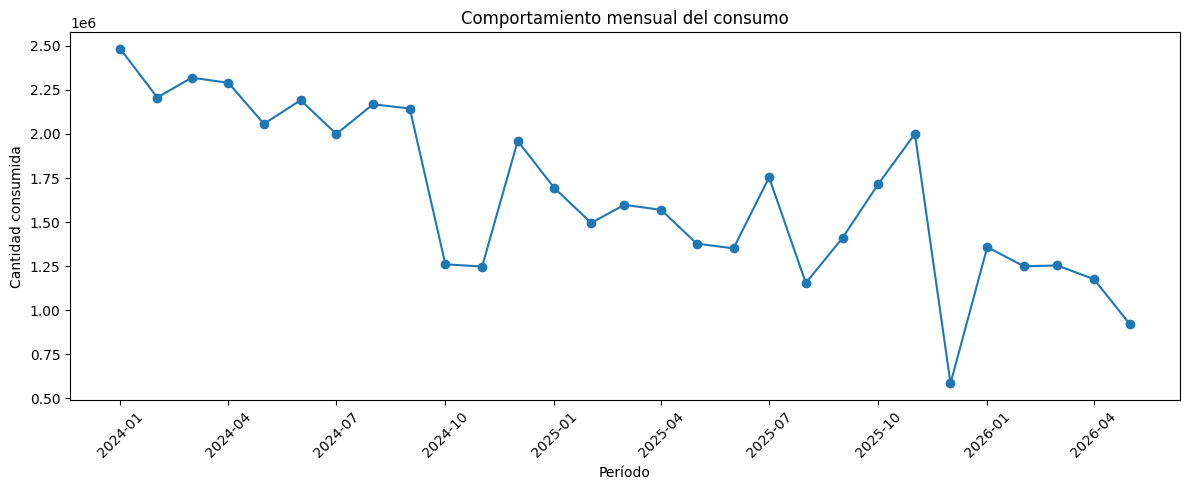

In [51]:
# GRÁFICA DEL COMPORTAMIENTO TEMPORAL


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.title("Comportamiento mensual del consumo")
plt.xlabel("Período")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [52]:
# IDENTIFICACIÓN DE CAMBIOS MENSUALES


cambios_mensuales = consumo_mensual.copy()

cambios_mensuales["Variacion_%"] = (
    cambios_mensuales["CANTIDAD"]
    .pct_change()
    .mul(100)
)

cambios_mensuales

,PERIODO,CANTIDAD,Variacion_%
0,2024-01-01,2482230.0,NaN
1,2024-02-01,2207099.0,-11.084025
2,2024-03-01,2319645.0,5.099273
3,2024-04-01,2290629.0,-1.250881
4,2024-05-01,2057523.0,-10.176506
5,2024-06-01,2192225.0,6.546804
6,2024-07-01,1999628.0,-8.785458
7,2024-08-01,2168699.0,8.455123
8,2024-09-01,2144575.0,-1.112372
9,2024-10-01,1260366.0,-41.230034


In [53]:
# CAMBIOS MENSUALES MÁS MARCADOS

# Mayores incrementos
mayores_aumentos = (
    cambios_mensuales[
        cambios_mensuales["Variacion_%"].notna()
    ]
    .sort_values("Variacion_%", ascending=False)
    .head(5)
)

# Mayores disminuciones
mayores_disminuciones = (
    cambios_mensuales[
        cambios_mensuales["Variacion_%"].notna()
    ]
    .sort_values("Variacion_%", ascending=True)
    .head(5)
)

print("MAYORES AUMENTOS MENSUALES")
print(mayores_aumentos)

print("\nMAYORES DISMINUCIONES MENSUALES")
print(mayores_disminuciones)

MAYORES AUMENTOS MENSUALES
      PERIODO   CANTIDAD  Variacion_%
24 2026-01-01  1358026.0   132.377149
11 2024-12-01  1960629.0    57.175107
18 2025-07-01  1753752.0    29.834079
20 2025-09-01  1410743.0    22.232735
21 2025-10-01  1714964.0    21.564594

MAYORES DISMINUCIONES MENSUALES
      PERIODO   CANTIDAD  Variacion_%
23 2025-12-01   584406.0   -70.794463
9  2024-10-01  1260366.0   -41.230034
19 2025-08-01  1154145.0   -34.189954
28 2026-05-01   922393.0   -21.543539
12 2025-01-01  1692443.0   -13.678569


In [54]:
# COMPORTAMIENTO DEL CONSUMO
# POR SERVICIO FARMACÉUTICO


# Validar la relación Bodega - Servicio Farmacéutico

bodegas_validacion = (
    bodegas[
        ["Bodega", "Servicio Farmaceutico"]
    ]
    .drop_duplicates()
    .sort_values("Bodega")
)

# Identificar bodegas con más de un Servicio Farmacéutico
bodegas_multiples = (
    bodegas_validacion
    .groupby("Bodega")["Servicio Farmaceutico"]
    .nunique()
)

bodegas_multiples = bodegas_multiples[
    bodegas_multiples > 1
]

print(
    "Número de bodegas con más de un Servicio Farmacéutico:",
    len(bodegas_multiples)
)

bodegas_multiples

Número de bodegas con más de un Servicio Farmacéutico: 0


,Servicio Farmaceutico
Bodega,


In [55]:
# CREAR CORRESPONDENCIA BODEGA - SERVICIO FARMACÉUTICO


mapa_servicio_farmaceutico = (
    bodegas[
        ["Bodega", "Servicio Farmaceutico"]
    ]
    .drop_duplicates(subset=["Bodega"])
    .set_index("Bodega")["Servicio Farmaceutico"]
)

print(
    "Bodegas incluidas en el mapa:",
    len(mapa_servicio_farmaceutico)
)

mapa_servicio_farmaceutico.head(10)

Bodegas incluidas en el mapa: 37


,Servicio Farmaceutico
Bodega,
130,Cirugia Ambulatoria
155,Cirugia Ambulatoria
820,Hospitalizacion
821,Urgencias
823,Hospitalizacion
824,NaN
825,Hospitalizacion
826,UCI-UCE
827,Hospitalizacion


In [56]:
# ASIGNAR SERVICIO FARMACÉUTICO A CADA REGISTRO


base_historica["BODEGA_KEY"] = pd.to_numeric(
    base_historica["BODEGA"],
    errors="coerce"
)

base_historica["SERVICIO_FARMACEUTICO"] = (
    base_historica["BODEGA_KEY"]
    .map(mapa_servicio_farmaceutico)
)

print(
    "Registros totales:",
    len(base_historica)
)

print(
    "Registros con Servicio Farmacéutico asignado:",
    base_historica["SERVICIO_FARMACEUTICO"].notna().sum()
)

print(
    "Registros sin Servicio Farmacéutico:",
    base_historica["SERVICIO_FARMACEUTICO"].isna().sum()
)

Registros totales: 11341686
Registros con Servicio Farmacéutico asignado: 11341686
Registros sin Servicio Farmacéutico: 0


In [57]:
# CONSUMO TOTAL POR SERVICIO FARMACÉUTICO


consumo_por_sf = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO")
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
    .sort_values("Consumo_total", ascending=False)
)

# Participación porcentual del consumo
consumo_por_sf["Participacion_%"] = (
    consumo_por_sf["Consumo_total"]
    / consumo_por_sf["Consumo_total"].sum()
    * 100
)

print(
    "Número de Servicios Farmacéuticos:",
    len(consumo_por_sf)
)

consumo_por_sf

Número de Servicios Farmacéuticos: 8


,SERVICIO_FARMACEUTICO,Registros,Consumo_total,Participacion_%
3,Hospitalizacion,6415564,20621808.0,42.969536
0,Almacen,50684,15270443.0,31.818929
6,UCI-UCE,2192881,5638164.0,11.748208
1,Cirugia,1481916,3912064.0,8.151544
7,Urgencias,1164861,2468920.0,5.144474
4,Nopbs,33901,62801.0,0.130858
2,Cirugia Ambulatoria,1799,17385.0,0.036225
5,Todas,80,109.0,0.000227


In [58]:
# VALIDACIÓN DE LOS SERVICIOS FARMACÉUTICOS


validacion_sf = (
    base_historica[
        ["BODEGA", "SERVICIO_FARMACEUTICO"]
    ]
    .drop_duplicates()
    .sort_values(
        ["SERVICIO_FARMACEUTICO", "BODEGA"]
    )
)

validacion_sf

,BODEGA,SERVICIO_FARMACEUTICO
1401125,885,Almacen
141,830,Cirugia
0,853,Cirugia
199031,866,Cirugia
1046433,845,Cirugia Ambulatoria
5674180,852,Cirugia Ambulatoria
11322069,857,Cirugia Ambulatoria
10939800,858,Cirugia Ambulatoria
6388057,875,Cirugia Ambulatoria
20,820,Hospitalizacion


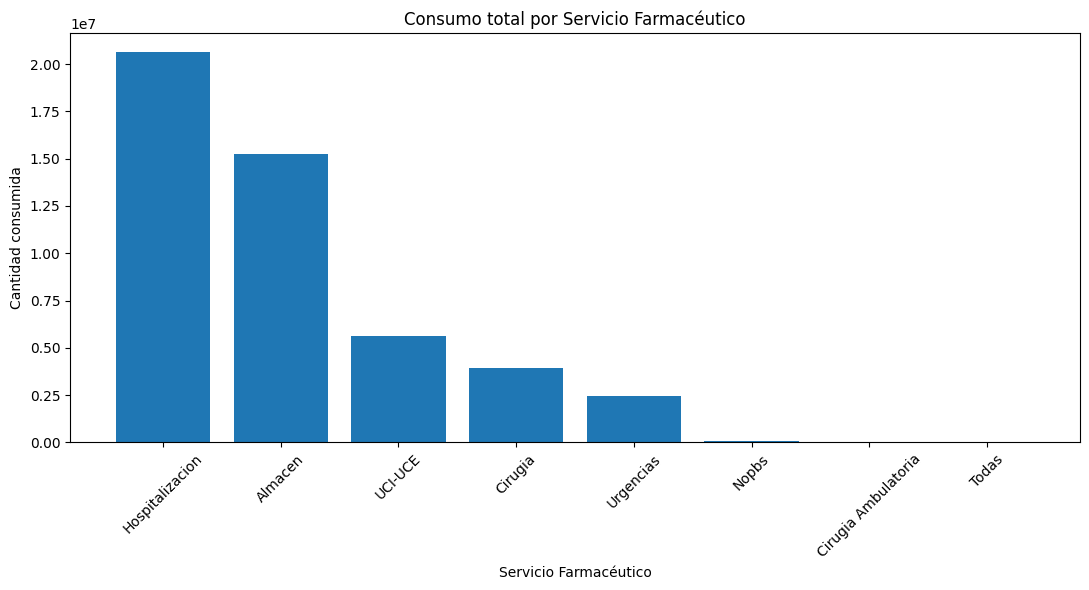

In [59]:
# GRÁFICA DEL CONSUMO POR SERVICIO FARMACÉUTICO


import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    consumo_por_sf["SERVICIO_FARMACEUTICO"],
    consumo_por_sf["Consumo_total"]
)

plt.title("Consumo total por Servicio Farmacéutico")
plt.xlabel("Servicio Farmacéutico")
plt.ylabel("Cantidad consumida")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [60]:
print(consumo_por_sf.to_string(index=False))

SERVICIO_FARMACEUTICO  Registros  Consumo_total  Participacion_%
      Hospitalizacion    6415564     20621808.0        42.969536
              Almacen      50684     15270443.0        31.818929
              UCI-UCE    2192881      5638164.0        11.748208
              Cirugia    1481916      3912064.0         8.151544
            Urgencias    1164861      2468920.0         5.144474
                Nopbs      33901        62801.0         0.130858
  Cirugia Ambulatoria       1799        17385.0         0.036225
                Todas         80          109.0         0.000227


In [61]:
# VALIDACIÓN DE LA DISTRIBUCIÓN POR SERVICIO


print("Registros de la base analítica:", len(base_historica))

print(
    "Suma de registros agrupados por Servicio Farmacéutico:",
    consumo_por_sf["Registros"].sum()
)

print(
    "Diferencia de registros:",
    len(base_historica) - consumo_por_sf["Registros"].sum()
)

print(
    "\nConsumo total de la base:",
    base_historica["CANTIDAD"].sum()
)

print(
    "Suma del consumo agrupado por Servicio Farmacéutico:",
    consumo_por_sf["Consumo_total"].sum()
)

print(
    "Diferencia de consumo:",
    base_historica["CANTIDAD"].sum()
    - consumo_por_sf["Consumo_total"].sum()
)

Registros de la base analítica: 11341686
Suma de registros agrupados por Servicio Farmacéutico: 11341686
Diferencia de registros: 0

Consumo total de la base: 47991694.0
Suma del consumo agrupado por Servicio Farmacéutico: 47991694.0
Diferencia de consumo: 0.0


In [62]:
productos_rotacion = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
    .sort_values("Consumo_total", ascending=False)
)

print("Número de productos analizados:", len(productos_rotacion))

productos_rotacion.head(20)

Número de productos analizados: 11887


,CODIGO_PROPIO,DES_MEDICAMENTO,Registros,Consumo_total
3055,99944,GUANTE VINILO TALLA M,10898,6626700.0
3363,110314,GUANTE VINILO TALLA L,9096,5412995.0
1328,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,3238,3911035.0
4484,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,6836,2681300.0
3362,110280,GUANTE VINILO TALLA S,5716,2635500.0
657,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,1712,1905505.0
1473,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,16795,1874796.0
1334,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,102212,1328763.0
812,9848,GASA PRECORTADA 10 X 10 UNIDAD,5420,1304863.0
505,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,550992,1077704.0


In [63]:
# FRECUENCIA MENSUAL DE CONSUMO POR PRODUCTO


frecuencia_productos = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])["PERIODO"]
    .nunique()
    .reset_index(name="Meses_con_consumo")
)

# Incorporar el consumo total
productos_rotacion = productos_rotacion.merge(
    frecuencia_productos,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

# Ordenar por frecuencia de consumo
productos_rotacion = productos_rotacion.sort_values(
    ["Meses_con_consumo", "Consumo_total"],
    ascending=[False, False]
)

print("Productos analizados:", len(productos_rotacion))
print("Meses del período de análisis:", base_historica["PERIODO"].nunique())

productos_rotacion.head(20)

Productos analizados: 11887
Meses del período de análisis: 29


,CODIGO_PROPIO,DES_MEDICAMENTO,Registros,Consumo_total,Meses_con_consumo
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,550992,1077704.0,29
10,9105,JERINGA DESECHABLE 5 ML CON AGUJA 21G X 1.,439809,917586.0,29
11,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,405876,886023.0,29
12,10140,ACETAMINOFEN 500MG TABLETA,434213,831598.0,29
13,35046,LANCETA DESECHABLE,301935,666960.0,29
16,3026,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,189907,337590.0,29
18,2089,ELECTRODO MONITOREO ADULTO,55605,314800.0,29
19,19004,JERINGA DESECHABLE 20 ML PUNTA ROSCA CON AGUJA...,163746,302201.0,29
21,100015271,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,178668,275606.0,29
25,2638,GUANTE CIRUJANO N. 7,86403,182432.0,29


In [64]:
# DISTRIBUCIÓN DE LA FRECUENCIA DE CONSUMO

distribucion_frecuencia = (
    productos_rotacion
    .groupby("Meses_con_consumo")
    .size()
    .reset_index(name="Numero_productos")
    .sort_values("Meses_con_consumo", ascending=False)
)

# Calcular porcentaje de productos
distribucion_frecuencia["Porcentaje_%"] = (
    distribucion_frecuencia["Numero_productos"]
    / distribucion_frecuencia["Numero_productos"].sum()
    * 100
)

print(
    "Total de productos:",
    distribucion_frecuencia["Numero_productos"].sum()
)

distribucion_frecuencia

Total de productos: 11887


,Meses_con_consumo,Numero_productos,Porcentaje_%
28,29,404,3.398671
27,28,133,1.118869
26,27,107,0.900143
25,26,84,0.706654
24,25,88,0.740305
23,24,77,0.647766
22,23,112,0.942206
21,22,95,0.799192
20,21,64,0.538403
19,20,66,0.555228


In [65]:
# INTENSIDAD DEL CONSUMO EN LOS MESES ACTIVOS


productos_rotacion["Consumo_promedio_mes_activo"] = (
    productos_rotacion["Consumo_total"]
    / productos_rotacion["Meses_con_consumo"]
)

print("Productos analizados:", len(productos_rotacion))

productos_rotacion[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Consumo_total",
        "Meses_con_consumo",
        "Consumo_promedio_mes_activo"
    ]
].head(20)

Productos analizados: 11887


,CODIGO_PROPIO,DES_MEDICAMENTO,Consumo_total,Meses_con_consumo,Consumo_promedio_mes_activo
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,1077704.0,29,37162.206897
10,9105,JERINGA DESECHABLE 5 ML CON AGUJA 21G X 1.,917586.0,29,31640.896552
11,9403,JERINGA DESECHABLE 10 ML 21G X 1 1/2,886023.0,29,30552.517241
12,10140,ACETAMINOFEN 500MG TABLETA,831598.0,29,28675.793103
13,35046,LANCETA DESECHABLE,666960.0,29,22998.620690
16,3026,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,337590.0,29,11641.034483
18,2089,ELECTRODO MONITOREO ADULTO,314800.0,29,10855.172414
19,19004,JERINGA DESECHABLE 20 ML PUNTA ROSCA CON AGUJA...,302201.0,29,10420.724138
21,100015271,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,275606.0,29,9503.655172
25,2638,GUANTE CIRUJANO N. 7,182432.0,29,6290.758621


In [66]:
# CLASIFICACIÓN DESCRIPTIVA DE LOS PATRONES DE FRECUENCIA DE CONSUMO

def clasificar_frecuencia(meses):
    if meses >= 24:
        return "Consumo sostenido"
    elif meses >= 12:
        return "Consumo frecuente"
    elif meses >= 4:
        return "Consumo intermitente"
    else:
        return "Consumo esporádico"


productos_rotacion["Patron_frecuencia"] = (
    productos_rotacion["Meses_con_consumo"]
    .apply(clasificar_frecuencia)
)

distribucion_patrones = (
    productos_rotacion
    .groupby("Patron_frecuencia")
    .size()
    .reset_index(name="Numero_productos")
)

distribucion_patrones["Porcentaje_%"] = (
    distribucion_patrones["Numero_productos"]
    / distribucion_patrones["Numero_productos"].sum()
    * 100
)

orden_patrones = [
    "Consumo sostenido",
    "Consumo frecuente",
    "Consumo intermitente",
    "Consumo esporádico"
]

distribucion_patrones["Orden"] = (
    distribucion_patrones["Patron_frecuencia"]
    .map({x: i for i, x in enumerate(orden_patrones)})
)

distribucion_patrones = (
    distribucion_patrones
    .sort_values("Orden")
    .drop(columns="Orden")
)

distribucion_patrones

,Patron_frecuencia,Numero_productos,Porcentaje_%
3,Consumo sostenido,893,7.512409
1,Consumo frecuente,1024,8.614453
2,Consumo intermitente,2482,20.879953
0,Consumo esporádico,7488,62.993186


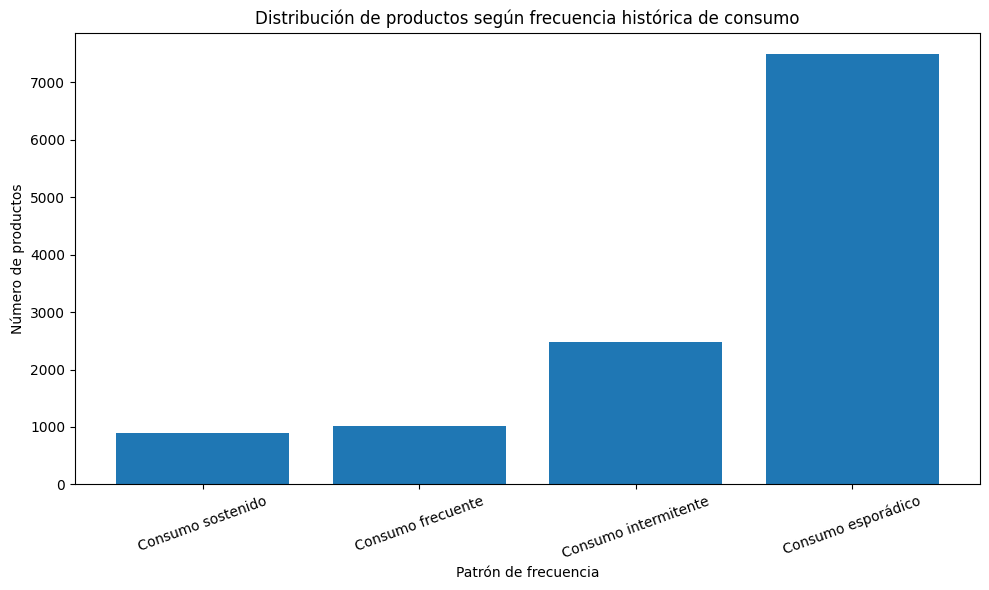

In [67]:
# GRÁFICA DE LOS PATRONES DE FRECUENCIA


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    distribucion_patrones["Patron_frecuencia"],
    distribucion_patrones["Numero_productos"]
)

plt.title("Distribución de productos según frecuencia histórica de consumo")
plt.xlabel("Patrón de frecuencia")
plt.ylabel("Número de productos")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [68]:
# CONSUMO TOTAL SEGÚN PATRÓN DE FRECUENCIA


consumo_por_patron = (
    productos_rotacion
    .groupby("Patron_frecuencia")
    .agg(
        Numero_productos=("CODIGO_PROPIO", "count"),
        Consumo_total=("Consumo_total", "sum")
    )
    .reset_index()
)

consumo_por_patron["Participacion_consumo_%"] = (
    consumo_por_patron["Consumo_total"]
    / consumo_por_patron["Consumo_total"].sum()
    * 100
)

orden_patrones = [
    "Consumo sostenido",
    "Consumo frecuente",
    "Consumo intermitente",
    "Consumo esporádico"
]

consumo_por_patron["Orden"] = (
    consumo_por_patron["Patron_frecuencia"]
    .map({x: i for i, x in enumerate(orden_patrones)})
)

consumo_por_patron = (
    consumo_por_patron
    .sort_values("Orden")
    .drop(columns="Orden")
)

consumo_por_patron

,Patron_frecuencia,Numero_productos,Consumo_total,Participacion_consumo_%
3,Consumo sostenido,893,41836454.0,87.174364
1,Consumo frecuente,1024,3813593.0,7.946360
2,Consumo intermitente,2482,1940659.0,4.043739
0,Consumo esporádico,7488,400988.0,0.835536


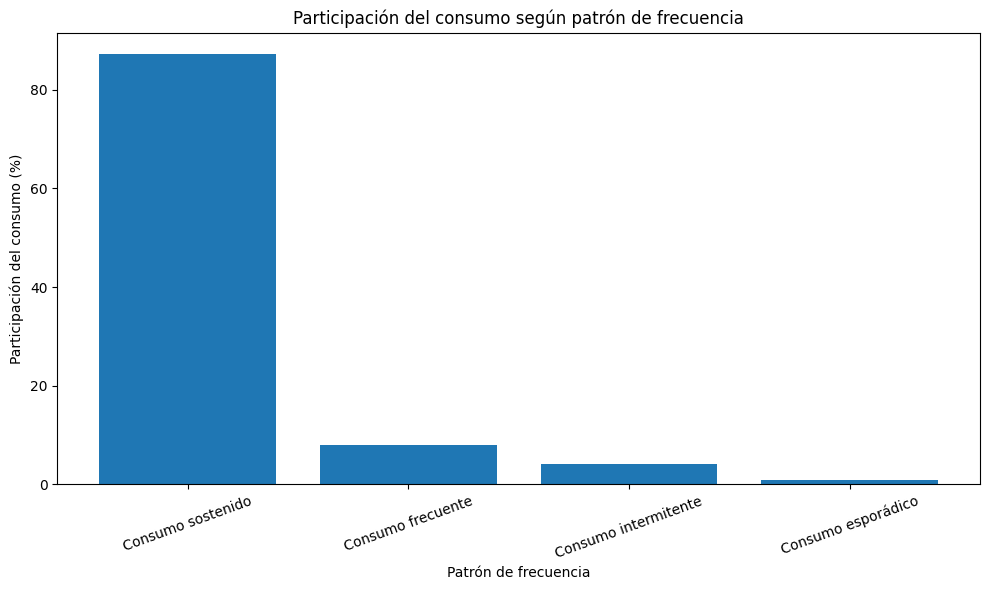

In [69]:
# PARTICIPACIÓN DEL CONSUMO SEGÚN PATRÓN


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    consumo_por_patron["Patron_frecuencia"],
    consumo_por_patron["Participacion_consumo_%"]
)

plt.title("Participación del consumo según patrón de frecuencia")
plt.xlabel("Patrón de frecuencia")
plt.ylabel("Participación del consumo (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [70]:
# RECONSTRUCCIÓN COMPLETA DEL ANÁLISIS
# DE ROTACIÓN


# 1. Universo de productos y consumo acumulado
productos_rotacion = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])
    .agg(
        Registros=("CANTIDAD", "count"),
        Consumo_total=("CANTIDAD", "sum")
    )
    .reset_index()
)

# 2. Número de meses con consumo
frecuencia_productos = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO"])["PERIODO"]
    .nunique()
    .reset_index(name="Meses_con_consumo")
)

# 3. Incorporar frecuencia a la tabla de productos
productos_rotacion = productos_rotacion.merge(
    frecuencia_productos,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

# 4. Consumo promedio durante los meses activos
productos_rotacion["Consumo_promedio_mes_activo"] = (
    productos_rotacion["Consumo_total"]
    / productos_rotacion["Meses_con_consumo"]
)

# 5. Clasificación descriptiva de frecuencia
def clasificar_frecuencia(meses):
    if meses >= 24:
        return "Consumo sostenido"
    elif meses >= 12:
        return "Consumo frecuente"
    elif meses >= 4:
        return "Consumo intermitente"
    else:
        return "Consumo esporádico"

productos_rotacion["Patron_frecuencia"] = (
    productos_rotacion["Meses_con_consumo"]
    .apply(clasificar_frecuencia)
)

# 6. Ordenar por consumo total
productos_rotacion = productos_rotacion.sort_values(
    "Consumo_total",
    ascending=False
).reset_index(drop=True)

# 7. Verificación
print("Productos analizados:", len(productos_rotacion))
print("\nDistribución de patrones:")
print(productos_rotacion["Patron_frecuencia"].value_counts())

print("\nColumnas disponibles:")
print(productos_rotacion.columns.tolist())

Productos analizados: 11887

Distribución de patrones:
Patron_frecuencia
Consumo esporádico      7488
Consumo intermitente    2482
Consumo frecuente       1024
Consumo sostenido        893
Name: count, dtype: int64

Columnas disponibles:
['CODIGO_PROPIO', 'DES_MEDICAMENTO', 'Registros', 'Consumo_total', 'Meses_con_consumo', 'Consumo_promedio_mes_activo', 'Patron_frecuencia']


In [71]:
# PRODUCTOS DE CONSUMO SOSTENIDO
# CON MAYOR CONSUMO ACUMULADO


top_sostenidos = (
    productos_rotacion[
        productos_rotacion["Patron_frecuencia"] == "Consumo sostenido"
    ]
    .sort_values("Consumo_total", ascending=False)
    .head(20)
    [
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Meses_con_consumo",
            "Consumo_total",
            "Consumo_promedio_mes_activo"
        ]
    ]
)

top_sostenidos

,CODIGO_PROPIO,DES_MEDICAMENTO,Meses_con_consumo,Consumo_total,Consumo_promedio_mes_activo
0,99944,GUANTE VINILO TALLA M,28,6626700.0,236667.857143
1,110314,GUANTE VINILO TALLA L,28,5412995.0,193321.250000
2,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,28,3911035.0,139679.821429
3,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,28,2681300.0,95760.714286
4,110280,GUANTE VINILO TALLA S,28,2635500.0,94125.000000
5,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,28,1905505.0,68053.750000
6,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,26,1874796.0,72107.538462
7,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,24,1328763.0,55365.125000
8,9848,GASA PRECORTADA 10 X 10 UNIDAD,25,1304863.0,52194.520000
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,29,1077704.0,37162.206897


In [72]:
# TABLA PARA EXPORTAR A EXCEL


tabla_excel = top_sostenidos.copy()

# Redondear el promedio a 2 decimales
tabla_excel["Consumo_promedio_mes_activo"] = (
    tabla_excel["Consumo_promedio_mes_activo"]
    .round(2)
)

# Eliminar el índice de pandas
tabla_excel = tabla_excel.reset_index(drop=True)

tabla_excel

,CODIGO_PROPIO,DES_MEDICAMENTO,Meses_con_consumo,Consumo_total,Consumo_promedio_mes_activo
0,99944,GUANTE VINILO TALLA M,28,6626700.0,236667.86
1,110314,GUANTE VINILO TALLA L,28,5412995.0,193321.25
2,30483,ESPARADRAPO ELASTICO ADHES 15 CM X 1000 CM,28,3911035.0,139679.82
3,41191082,TOALLITA ANTISEPTICA ESTERIL REF 101.06,28,2681300.0,95760.71
4,110280,GUANTE VINILO TALLA S,28,2635500.0,94125.00
5,6003,ESPARADRAPO ELASTICO ADHES 10 CM X 1000 CM,28,1905505.0,68053.75
6,32568,IOPRAMIDA SOLUCION INYECTABLE 300MG/50 ML X ML,26,1874796.0,72107.54
7,30513,GASA ESTERIL 10CMX10CM 16 PLY QUALIMED,24,1328763.0,55365.12
8,9848,GASA PRECORTADA 10 X 10 UNIDAD,25,1304863.0,52194.52
9,5059,SODIO CLORURO 0.9% SOLUCION INYECTABLE BOLSA X...,29,1077704.0,37162.21


In [73]:
# ANÁLISIS DE VARIABILIDAD
# CONSUMO MENSUAL POR PRODUCTO


consumo_mensual_producto = (
    base_historica
    .groupby(["CODIGO_PROPIO", "DES_MEDICAMENTO", "PERIODO"])["CANTIDAD"]
    .sum()
    .reset_index()
)

print("Registros de consumo mensual por producto:", len(consumo_mensual_producto))

consumo_mensual_producto.head(20)

Registros de consumo mensual por producto: 68888


,CODIGO_PROPIO,DES_MEDICAMENTO,PERIODO,CANTIDAD
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2025-12-01,34.0
1,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-01-01,3.0
2,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-02-01,17.0
3,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-03-01,5.0
4,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-04-01,6.0
5,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2026-05-01,2.0
6,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-01-01,8.0
7,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-02-01,35.0
8,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-03-01,43.0
9,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),2024-04-01,34.0


In [74]:
# MATRIZ DE CONSUMO MENSUAL
# PRODUCTO × PERÍODO


matriz_consumo = (
    consumo_mensual_producto
    .pivot_table(
        index=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
        columns="PERIODO",
        values="CANTIDAD",
        aggfunc="sum",
        fill_value=0
    )
)

print("Productos:", matriz_consumo.shape[0])
print("Períodos:", matriz_consumo.shape[1])

matriz_consumo.head()

Productos: 11887
Períodos: 29


PERIODO                                                           2024-01-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                  8.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       107.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3827.0   

PERIODO                                                           2024-02-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 35.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       140.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3028.0   

PERIODO                                                           2024-03-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 43.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       143.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3499.0   

PERIODO                                                           2024-04-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 34.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       135.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 3944.0   

PERIODO                                                           2024-05-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 29.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       139.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 2855.0   

PERIODO                                                           2024-06-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 48.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       150.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 4077.0   

PERIODO                                                           2024-07-01  \
CODIGO_PROPIO DES_MEDICAMENTO                                                  
11            ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS                      0.0   
              ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J)                 32.0   
55            ACETAMINOFEN 150MG/5ML (3%) JARABE  FRASCO X 60 ML       143.0   
              ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML          0.0   
64            ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA                 4278.0   

PERIODO                                                           2024-08

In [75]:
# CÁLCULO DE LA VARIABILIDAD DEL CONSUMO

# Seleccionar únicamente las columnas correspondientes
# a los 29 períodos mensuales
columnas_periodos = matriz_consumo.columns

# Promedio mensual del consumo
variabilidad_productos = matriz_consumo.copy()

variabilidad_productos["Promedio_mensual"] = (
    matriz_consumo[columnas_periodos].mean(axis=1)
)

# Desviación estándar mensual
variabilidad_productos["Desviacion_estandar"] = (
    matriz_consumo[columnas_periodos].std(axis=1)
)

# Coeficiente de variación
variabilidad_productos["CV_%"] = (
    variabilidad_productos["Desviacion_estandar"]
    / variabilidad_productos["Promedio_mensual"]
    * 100
)

variabilidad_productos = (
    variabilidad_productos
    .reset_index()
)

print("Productos analizados:", len(variabilidad_productos))

variabilidad_productos[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Promedio_mensual",
        "Desviacion_estandar",
        "CV_%"
    ]
].head(20)

Productos analizados: 11887


PERIODO,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%
0,11,ACERO QUIRURGICO 5 4X40-45CM CCS-CDSS,2.310345,6.980091,302.123356
1,11,ACERO QUIRURGICO 5 4X45CM CCS M653G (J&J),27.034483,18.399307,68.058660
2,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 6...,62.344828,60.326064,96.761939
3,55,ACETAMINOFEN 150MG/5ML (3%) JARABE FRASCO X 60 ML,21.620690,33.744220,156.073747
4,64,ACETAMINOFEN 500MG+CAFEINA 65MG TABLETA,2169.827586,1423.493792,65.604005
5,87,ACETIL SALICILICO ACIDO 100 MG TABLETA,1833.827586,407.047739,22.196620
6,101,ACETILCISTEINA 300 MG/3 ML SOLUCION INYECTABLE,181.413793,158.498201,87.368330
7,178,ADRENALINA 1MG/ML 1ML SOLUCION INYECTABLE,182.137931,128.801543,70.716485
8,178,ADRENALINA 1MG/ML 1ML SOLUCION INYECTABLE AMPOLLA,93.068966,156.564211,168.223865
9,212,AGUA ESTERIL SOLUCION INYECTABLE 500 ML,1075.137931,312.165218,29.034899


In [76]:
# DISTRIBUCIÓN DEL COEFICIENTE DE VARIACIÓN


resumen_cv = pd.DataFrame({
    "Indicador": [
        "CV mínimo",
        "CV P25",
        "CV mediana",
        "CV P75",
        "CV P90",
        "CV P95",
        "CV máximo"
    ],
    "Valor": [
        variabilidad_productos["CV_%"].min(),
        variabilidad_productos["CV_%"].quantile(0.25),
        variabilidad_productos["CV_%"].median(),
        variabilidad_productos["CV_%"].quantile(0.75),
        variabilidad_productos["CV_%"].quantile(0.90),
        variabilidad_productos["CV_%"].quantile(0.95),
        variabilidad_productos["CV_%"].max()
    ]
})

resumen_cv

,Indicador,Valor
0,CV mínimo,17.653286
1,CV P25,222.967006
2,CV mediana,373.927036
3,CV P75,538.516481
4,CV P90,538.516481
5,CV P95,538.516481
6,CV máximo,538.516481


In [77]:
# DISTRIBUCIÓN DEL COEFICIENTE DE VARIACIÓN


intervalos_cv = [0, 25, 50, 100, 200, 300, 400, 500, 600]

etiquetas_cv = [
    "0-25%",
    "25-50%",
    "50-100%",
    "100-200%",
    "200-300%",
    "300-400%",
    "400-500%",
    "500-600%"
]

variabilidad_productos["Rango_CV"] = pd.cut(
    variabilidad_productos["CV_%"],
    bins=intervalos_cv,
    labels=etiquetas_cv,
    include_lowest=True
)

distribucion_cv = (
    variabilidad_productos
    .groupby("Rango_CV", observed=False)
    .agg(
        Numero_productos=("CODIGO_PROPIO", "count")
    )
    .reset_index()
)

distribucion_cv["Porcentaje_%"] = (
    distribucion_cv["Numero_productos"]
    / len(variabilidad_productos)
    * 100
)

distribucion_cv

,Rango_CV,Numero_productos,Porcentaje_%
0,0-25%,20,0.168251
1,25-50%,236,1.985362
2,50-100%,763,6.418777
3,100-200%,1585,13.333894
4,200-300%,1965,16.530664
5,300-400%,1993,16.766215
6,400-500%,195,1.640448
7,500-600%,5130,43.156389


In [80]:
# INCORPORAR PATRÓN DE FRECUENCIA
# A LA BASE DE VARIABILIDAD


patrones_producto = productos_rotacion[
    [
        "CODIGO_PROPIO",
        "DES_MEDICAMENTO",
        "Patron_frecuencia"
    ]
].drop_duplicates(
    subset=["CODIGO_PROPIO", "DES_MEDICAMENTO"]
)

variabilidad_productos = variabilidad_productos.merge(
    patrones_producto,
    on=["CODIGO_PROPIO", "DES_MEDICAMENTO"],
    how="left"
)

print("Productos analizados:", len(variabilidad_productos))
print(
    "Productos con patrón asignado:",
    variabilidad_productos["Patron_frecuencia"].notna().sum()
)
print(
    "Productos sin patrón:",
    variabilidad_productos["Patron_frecuencia"].isna().sum()
)

Productos analizados: 11887
Productos con patrón asignado: 11887
Productos sin patrón: 0


In [81]:
# RELACIÓN ENTRE FRECUENCIA Y VARIABILIDAD


relacion_frecuencia_variabilidad = pd.crosstab(
    variabilidad_productos["Rango_CV"],
    variabilidad_productos["Patron_frecuencia"]
)

relacion_frecuencia_variabilidad

Patron_frecuencia,Consumo esporádico,Consumo frecuente,Consumo intermitente,Consumo sostenido
Rango_CV,,,,
0-25%,0,0,0,20
25-50%,0,0,0,236
50-100%,0,213,0,550
100-200%,0,769,735,81
200-300%,350,37,1573,5
300-400%,1827,4,161,1
400-500%,181,1,13,0
500-600%,5130,0,0,0


In [82]:
# PORCENTAJE DE CADA PATRÓN
# DENTRO DE CADA RANGO DE CV


relacion_frecuencia_variabilidad_pct = (
    pd.crosstab(
        variabilidad_productos["Rango_CV"],
        variabilidad_productos["Patron_frecuencia"],
        normalize="index"
    ) * 100
)

relacion_frecuencia_variabilidad_pct = (
    relacion_frecuencia_variabilidad_pct.round(2)
)

relacion_frecuencia_variabilidad_pct

Patron_frecuencia,Consumo esporádico,Consumo frecuente,Consumo intermitente,Consumo sostenido
Rango_CV,,,,
0-25%,0.00,0.00,0.00,100.00
25-50%,0.00,0.00,0.00,100.00
50-100%,0.00,27.92,0.00,72.08
100-200%,0.00,48.52,46.37,5.11
200-300%,17.81,1.88,80.05,0.25
300-400%,91.67,0.20,8.08,0.05
400-500%,92.82,0.51,6.67,0.00
500-600%,100.00,0.00,0.00,0.00


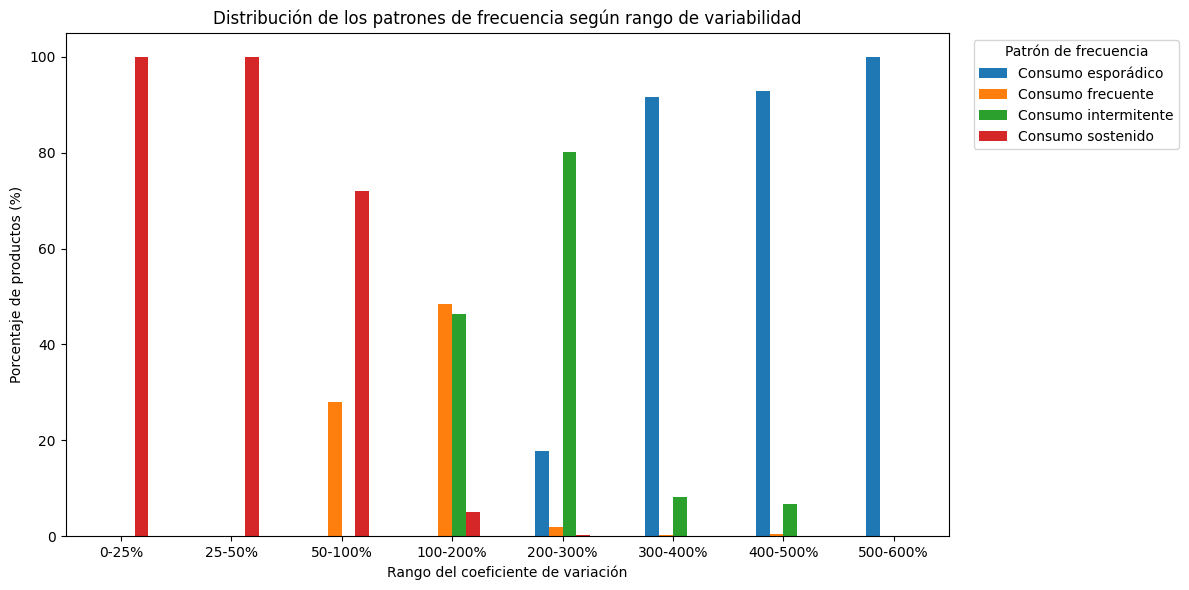

In [83]:
# RELACIÓN ENTRE FRECUENCIA Y VARIABILIDAD


relacion_frecuencia_variabilidad_pct.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Distribución de los patrones de frecuencia según rango de variabilidad"
)

plt.xlabel("Rango del coeficiente de variación")
plt.ylabel("Porcentaje de productos (%)")
plt.xticks(rotation=0)

plt.legend(
    title="Patrón de frecuencia",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [84]:
# PRODUCTOS CON MAYOR VARIABILIDAD


# Ordenar los productos por coeficiente de variación
# de mayor a menor
mayor_variabilidad = (
    variabilidad_productos[
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Promedio_mensual",
            "Desviacion_estandar",
            "CV_%",
            "Patron_frecuencia"
        ]
    ]
    .sort_values("CV_%", ascending=False)
    .head(20)
)

mayor_variabilidad

,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%,Patron_frecuencia
707,8240,AMOXICILINA-AC CLAVULANICO 500/125 MG TAB,1.310345,7.056423,538.516481,Consumo esporádico
721,8678,AGUJA DESECHABLE HIPODERMICA N 27 G X 1,13.655172,73.535354,538.516481,Consumo esporádico
6027,100015289,TORNILLO BLOQUEO 4.0 X 42MM REF 661042,0.034483,0.185695,538.516481,Consumo esporádico
3751,250079,TORN. CORTICAL 4.5MM X 24MM REF TC4524,0.068966,0.371391,538.516481,Consumo esporádico
7708,100018504,TORNILLO CANULADO 3.5 RC L 48 REF 11103SC3500-...,0.034483,0.185695,538.516481,Consumo esporádico
1798,40102,CATETER DIAGNOSTICO AR2-AL2,0.034483,0.185695,538.516481,Consumo esporádico
7130,100017670,SISTEMA DE CIERRE DE OREJUELA AURICULAR IZQUIE...,0.034483,0.185695,538.516481,Consumo esporádico
7137,100017682,BALON CORONARIO CORTANTE WOLVERINE 2.50 X 10 M...,0.034483,0.185695,538.516481,Consumo esporádico
7139,100017685,"BALON CORONARIO CORTANTE WOLVERINE 2,0 X 15 MM...",0.034483,0.185695,538.516481,Consumo esporádico
7935,100018773,CLAVO INTRAMEDULAR DE HUMERO DE 9X160 MM MAGIC...,0.034483,0.185695,538.516481,Consumo esporádico


In [85]:
# VARIABILIDAD EN PRODUCTOS DE CONSUMO
# FRECUENTE Y SOSTENIDO


variabilidad_recurrente = (
    variabilidad_productos[
        variabilidad_productos["Patron_frecuencia"].isin(
            ["Consumo frecuente", "Consumo sostenido"]
        )
    ][
        [
            "CODIGO_PROPIO",
            "DES_MEDICAMENTO",
            "Promedio_mensual",
            "Desviacion_estandar",
            "CV_%",
            "Patron_frecuencia"
        ]
    ]
    .sort_values("CV_%", ascending=False)
    .head(20)
)

print(
    "Productos frecuentes y sostenidos analizados:",
    len(
        variabilidad_productos[
            variabilidad_productos["Patron_frecuencia"].isin(
                ["Consumo frecuente", "Consumo sostenido"]
            )
        ]
    )
)

variabilidad_recurrente

Productos frecuentes y sostenidos analizados: 1917


,CODIGO_PROPIO,DES_MEDICAMENTO,Promedio_mensual,Desviacion_estandar,CV_%,Patron_frecuencia
156,1653,CLOZAPINA 25 MG TABLETA,11.758621,48.767418,414.737575,Consumo frecuente
46,652,ARIPIPRAZOL 15 MG TABLETA,5.344828,18.287927,342.161216,Consumo frecuente
847,10314,GUANTE LATEX TALLA L,2044.827586,6972.629459,340.988624,Consumo frecuente
3118,102199,LINER SEMIRRIGIDO CON VALVULA 1500 CC,12.482759,42.364592,339.384850,Consumo frecuente
826,10088,APLICADORES CON ALGODON,139.758621,446.444658,319.439800,Consumo sostenido
4227,1591345,EMULSION LIPIDICA 20 % MCT/LCT (LIPOFUNDIN) X ...,3.034483,9.279327,305.796007,Consumo frecuente
500,4926,SEDA NEGRA TRENZADA 4-0 CON AGUJA DE 3/8 CIRC...,4.896552,14.148056,288.939171,Consumo frecuente
947,11402,APOSITO DE CARBON ACTIVADO CON PLATA 10.5X19CM...,7.379310,20.492880,277.707251,Consumo frecuente
665,6062,GENTAMICINA SULFATO 40 MG/ML SOLUCION INYECTABLE,5.034483,13.607988,270.295654,Consumo frecuente
1372,30888,SONDA NELATON N 4,2.413793,6.455990,267.462430,Consumo frecuente


In [87]:
# Ver las variables que actualmente existen en memoria
%whos DataFrame

Variable                               Type         Data/Info
-------------------------------------------------------------
base_2024                              DataFrame            CODIGO_PROPIO    <...>5670011 rows x 9 columns]
base_historica                         DataFrame             CODIGO_PROPIO   <...>341686 rows x 11 columns]
bodegas                                DataFrame        Bodega               <...>         No        8585  
bodegas_validacion                     DataFrame        Bodega Servicio Farma<...>585                   NaN
cambios_mensuales                      DataFrame          PERIODO   CANTIDAD <...>1   922393.0   -21.543539
cantidad_uno                           DataFrame       AÑO_REAL  Registros  R<...>01              69.931026
comparacion_ene_may                    DataFrame        AÑO  Consumo_total  P<...>   1191718.4   -22.942452
consumo_anual                          DataFrame        AÑO  Consumo_total  P<...>58592.0      1.191718e+06
consumo_ene_

In [88]:
# Mostrar la base consolidada de consumo mensual
consumo_mensual

,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [89]:
print("Número de períodos:", len(consumo_mensual))
display(consumo_mensual)

Número de períodos: 29


,PERIODO,CANTIDAD
0,2024-01-01,2482230.0
1,2024-02-01,2207099.0
2,2024-03-01,2319645.0
3,2024-04-01,2290629.0
4,2024-05-01,2057523.0
5,2024-06-01,2192225.0
6,2024-07-01,1999628.0
7,2024-08-01,2168699.0
8,2024-09-01,2144575.0
9,2024-10-01,1260366.0


In [94]:
consumo_mensual = (
    base_historica
    .groupby("PERIODO", as_index=False)["CANTIDAD"]
    .sum()
    .sort_values("PERIODO")
)

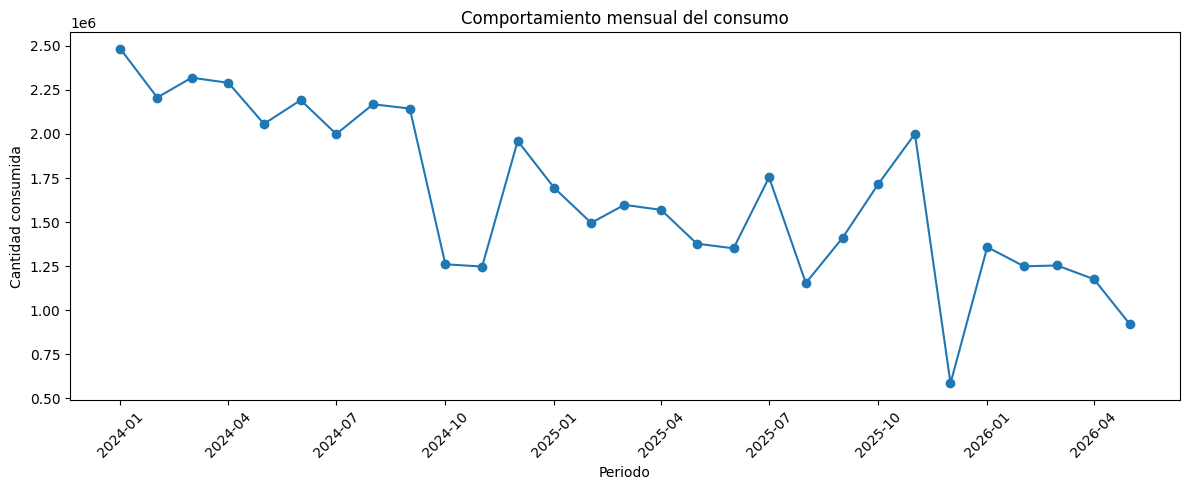

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    consumo_mensual["PERIODO"],
    consumo_mensual["CANTIDAD"],
    marker="o"
)

plt.xlabel("Periodo")
plt.ylabel("Cantidad consumida")
plt.title("Comportamiento mensual del consumo")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
base_historica.columns.tolist()

['CODIGO_PROPIO',
 'DES_MEDICAMENTO',
 'CANTIDAD',
 'BODEGA',
 'DES_UF',
 'MES',
 'AÑO',
 'MES_NUMERO',
 'PERIODO',
 'BODEGA_KEY',
 'SERVICIO_FARMACEUTICO']

In [97]:
comparacion_ene_may.columns.tolist()

['AÑO', 'Consumo_total', 'Promedio_mensual', 'Variacion_%']

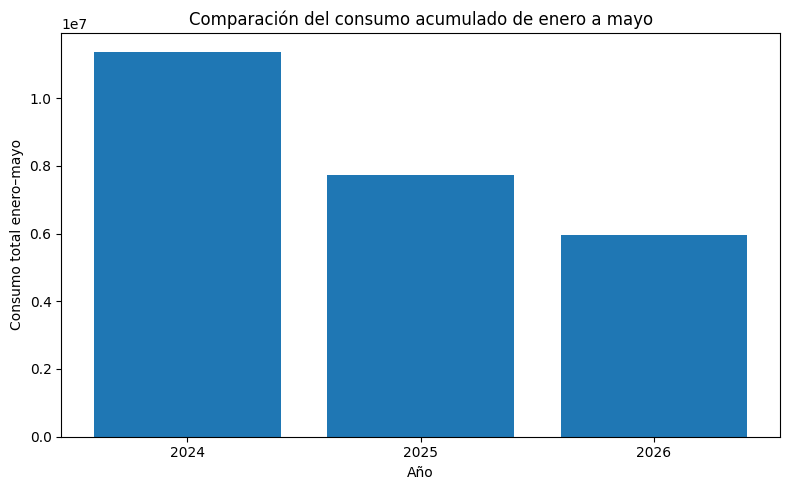

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparacion_ene_may["AÑO"].astype(str),
    comparacion_ene_may["Consumo_total"]
)

plt.xlabel("Año")
plt.ylabel("Consumo total enero–mayo")
plt.title("Comparación del consumo acumulado de enero a mayo")

plt.tight_layout()
plt.show()

In [101]:
consumo_servicio = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO", as_index=False)["CANTIDAD"]
    .sum()
    .sort_values("CANTIDAD", ascending=False)
)

consumo_servicio

,SERVICIO_FARMACEUTICO,CANTIDAD
3,Hospitalizacion,20621808.0
0,Almacen,15270443.0
6,UCI-UCE,5638164.0
1,Cirugia,3912064.0
7,Urgencias,2468920.0
4,Nopbs,62801.0
2,Cirugia Ambulatoria,17385.0
5,Todas,109.0


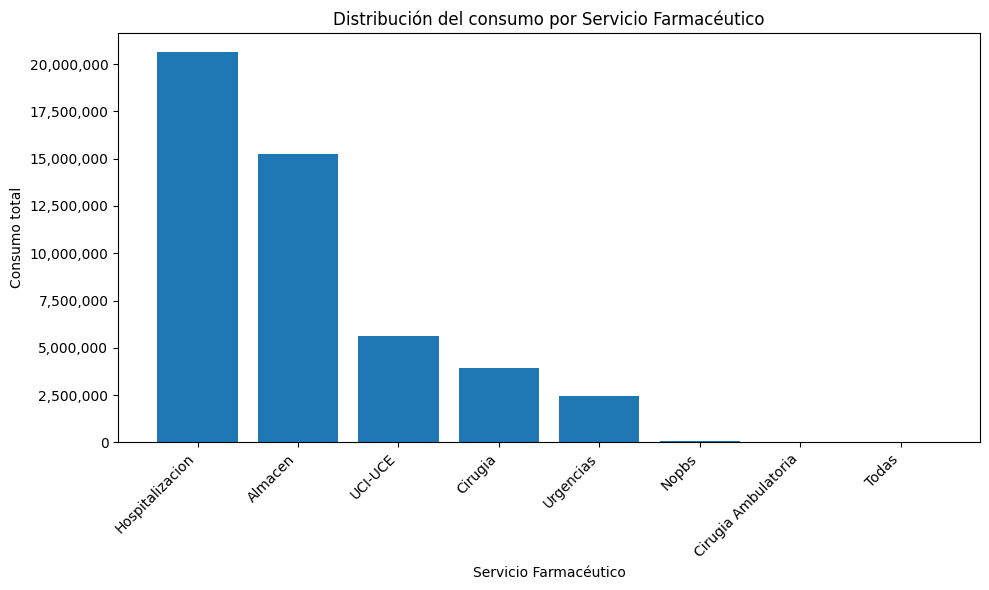

In [102]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 6))

plt.bar(
    consumo_servicio["SERVICIO_FARMACEUTICO"],
    consumo_servicio["CANTIDAD"]
)

plt.xlabel("Servicio Farmacéutico")
plt.ylabel("Consumo total")
plt.title("Distribución del consumo por Servicio Farmacéutico")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter('{x:,.0f}')
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [104]:
# Validación de la distribución por Servicio Farmacéutico

registros_base = len(base_historica)

registros_agrupados = (
    base_historica
    .groupby("SERVICIO_FARMACEUTICO")
    .size()
    .sum()
)

consumo_base = base_historica["CANTIDAD"].sum()

consumo_agrupado = consumo_servicio["CANTIDAD"].sum()

print("Registros de la base:", registros_base)
print("Registros agrupados:", registros_agrupados)
print("Diferencia de registros:", registros_base - registros_agrupados)

print()

print("Consumo total de la base:", consumo_base)
print("Consumo total agrupado:", consumo_agrupado)
print("Diferencia de consumo:", consumo_base - consumo_agrupado)

Registros de la base: 11341686
Registros agrupados: 11341686
Diferencia de registros: 0

Consumo total de la base: 47991694.0
Consumo total agrupado: 47991694.0
Diferencia de consumo: 0.0
